# Dengue Early-Warning System: reproducible modelling notebook
Runs locally (no Colab). Uses the project's `src/` modules so notebook, app and tests share one code path.

**Flow:** data audit -> lag features (+verification) -> EDA of the 2-4 week lag -> chronological split -> model & feature-set comparison -> test -> risk tiers, intervals, drivers.

In [1]:
import sys, json, warnings; warnings.filterwarnings('ignore')
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from src import config as C
from src.features import load_raw, build_dataset, add_target, feature_sets
sns.set_theme(style='whitegrid')

## 1. Data audit

In [2]:
raw = load_raw()
print(raw.shape, raw.date.min().date(), raw.date.max().date(), raw.ward_id.nunique(), 'wards')
print('missing:', int(raw.isna().sum().sum()), '| duplicate ward-weeks:', int(raw.duplicated(['ward_id','date']).sum()))
print('weekly continuity per ward:', raw.groupby('ward_id').date.apply(lambda s: (s.diff().dropna()==pd.Timedelta(days=7)).all()).all())
print('zero-case share:', round((raw.dengue_cases==0).mean(),3))
raw.describe().T[['mean','std','min','max']]

(31320, 12) 2016-01-04 2025-12-29 60 wards
missing: 0 | duplicate ward-weeks: 0
weekly continuity per ward: True
zero-case share: 0.58


,mean,std,min,max
date,2020-12-31 12:00:00,NaN,2016-01-04 00:00:00,2025-12-29 00:00:00
population_density_sqkm,43157.733333,14865.377799,18314.0,74252.0
water_logging_risk_index,0.579333,0.237903,0.22,0.94
sanitation_score,0.554667,0.191597,0.25,0.88
avg_temp_c,26.922804,4.482042,15.74,37.51
max_temp_c,31.889061,4.516627,23.12,40.79
min_temp_c,21.949425,4.527965,13.06,31.64
rainfall_mm,35.630268,50.237519,0.0,268.83
relative_humidity_pct,71.176132,12.96861,41.84,99.0
dengue_cases,2.636398,4.607737,0.0,41.0


## 2. Ward-level lag / rolling features and verification
Lags are computed with `groupby('ward_id').shift(k)`; the checks below fail loudly on leakage across wards or time.

In [3]:
df = build_dataset(with_history=True)
x = df[df.ward_id=='CCC_Ward_01'].reset_index(drop=True)
assert np.allclose(x.rain_lag_3w[3:], x.rainfall_mm.shift(3)[3:])
assert x.rain_lag_3w[:3].isna().all()            # first weeks of a ward are NaN, not borrowed from another ward
print('lag checks passed; feature table', df.shape)
print({k: len(v) for k, v in feature_sets(df).items()}, 'features per configuration')

lag checks passed; feature table (31320, 58)
{'weather_only': 47, 'weather_no_static': 44, 'weather_plus_history': 52} features per configuration


## 3. The 2-4 week breeding clock in the data

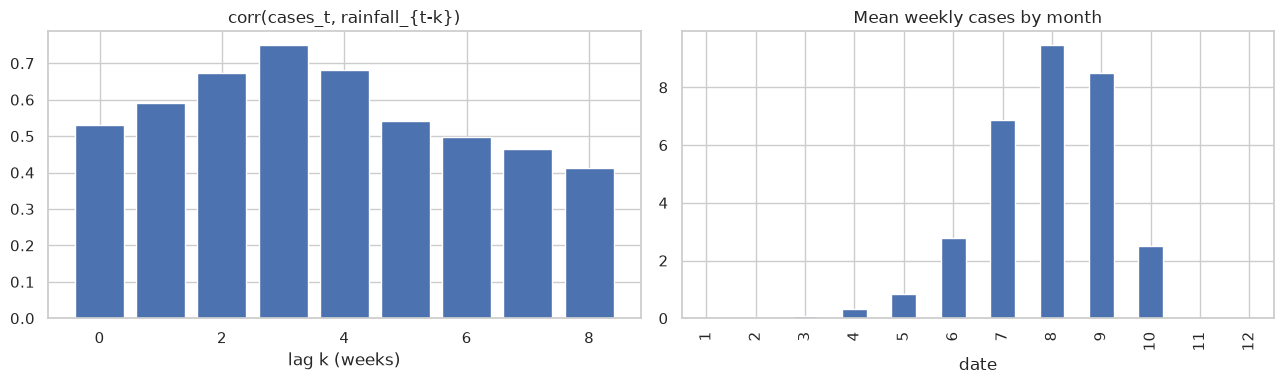

peak lag: 3 weeks


In [4]:
d = raw.copy(); g = d.groupby('ward_id')
lag_corr = {k: d.dengue_cases.corr(g.rainfall_mm.shift(k)) for k in range(0, 9)}
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].bar(list(lag_corr), list(lag_corr.values())); ax[0].set_title('corr(cases_t, rainfall_{t-k})'); ax[0].set_xlabel('lag k (weeks)')
raw.groupby(raw.date.dt.month).dengue_cases.mean().plot.bar(ax=ax[1], title='Mean weekly cases by month'); plt.tight_layout(); plt.show()
print('peak lag:', max(lag_corr, key=lag_corr.get), 'weeks')

## 4. Chronological split (4-week purge gap)

In [5]:
from src.train import split_masks
y = add_target(df); tr, va, ts = split_masks(df, y)
okf = df[feature_sets(df)['weather_only']].notna().all(axis=1)
for n, m in [('train', tr&okf), ('val', va&okf), ('test', ts&okf)]:
    print(f"{n:5s} {df.loc[m,'date'].min().date()} -> {df.loc[m,'date'].max().date()}  rows={int(m.sum())}")

train 2016-02-29 -> 2022-11-28  rows=21180
val   2023-01-02 -> 2024-05-27  rows=4440
test  2024-07-01 -> 2025-12-01  rows=4500


## 5. Train, compare, select, evaluate
`src.train.main()` runs the whole experiment (~1-2 min): model x feature-set comparison on **validation**, selection, conformal calibration on validation, refit on train+val, **single** test evaluation, rolling-origin CV, grouped importance, and saves `models/dengue_bundle.joblib` + `reports/`.

In [6]:
from src.train import main
main()

rows train/val/test = 21180/4440/4500
-                      Mean baseline        MAE=10.122 RMSE=13.365 R2=-0.008
-                      Persistence (cases_t x horizons) MAE=5.380 RMSE=11.398 R2=0.267
-                      Seasonal-naive (52w earlier) MAE=3.471 RMSE=7.191 R2=0.708


weather_only           Ridge                MAE=3.085 RMSE=5.723 R2=0.815


weather_only           RandomForest         MAE=1.966 RMSE=4.023 R2=0.909


weather_only           ExtraTrees           MAE=2.045 RMSE=4.201 R2=0.900


weather_only           HistGB (squared)     MAE=1.865 RMSE=3.816 R2=0.918


weather_only           HistGB (Poisson)     MAE=1.825 RMSE=3.804 R2=0.918
weather_no_static      Ridge                MAE=3.071 RMSE=6.175 R2=0.785


... (8 outputs left out)

[Week 3 ahead] TEST n=4500 MAE=1.207 RMSE=2.254 R2=0.722 cov=0.964 w=5.6 HC rec/prec/F1=0.81/0.73/0.77 FAR=0.086 [cqr; tiers (0.6, 0.8, 0.9)]


[Week 4 ahead] TEST n=4500 MAE=1.344 RMSE=2.568 R2=0.624 cov=0.966 w=5.8 HC rec/prec/F1=0.84/0.67/0.75 FAR=0.111 [cqr; tiers (0.6, 0.8, 0.9)]


                      fold     n    MAE   RMSE     R2  persistence_MAE  \
0  train<2021 -> test 2021  3120  1.879  3.427  0.865            4.483   
1  train<2022 -> test 2022  3120  3.111  6.190  0.803            6.627   
2  train<2023 -> test 2023  3120  2.275  4.459  0.913            7.105   
3  train<2024 -> test 2024  3180  1.911  3.701  0.867            4.809   

   seasonal_naive_MAE  
0               2.810  
1               4.676  
2               4.385  
3               4.110  


done in 110s


### Validation comparison (main window: cases summed over weeks 2-4 ahead)

In [7]:
pd.read_csv(ROOT/'reports/model_comparison_validation.csv').round(3)

,features,model,n_val,MAE,RMSE,R2
0,weather_only,HistGB (Poisson),4440,1.825,3.804,0.918
1,weather_plus_history,HistGB (Poisson),4440,1.860,3.881,0.915
2,weather_only,HistGB (squared),4440,1.865,3.816,0.918
3,weather_plus_history,HistGB (squared),4440,1.873,3.826,0.917
4,weather_only,RandomForest,4440,1.966,4.023,0.909
5,weather_plus_history,ExtraTrees,4440,2.031,4.151,0.903
6,weather_only,ExtraTrees,4440,2.045,4.201,0.900
7,weather_no_static,HistGB (Poisson),4440,2.500,5.568,0.825
8,weather_no_static,HistGB (squared),4440,2.580,5.550,0.826
9,weather_no_static,ExtraTrees,4440,2.602,5.609,0.822


**Findings.** Static ward attributes matter (removing them raises validation MAE sharply). Reported-case history adds nothing beyond weather + ward attributes, so the weather-only model is chosen (also deployable to wards with no surveillance).

In [8]:
M = json.loads((ROOT/'reports/metrics.json').read_text())
print('selected:', M['selected'])
pd.DataFrame(M['test_by_window']).T[['n','MAE','RMSE','R2','interval_coverage','interval_width','tier_exact_accuracy','tier_within_one','HC_recall','HC_precision','HC_F1','HC_false_alarm_rate']].round(3)

selected: {'model': 'HistGB (Poisson)', 'features': 'weather_only', 'history_adopted': False, 'n_features': 47}


,n,MAE,RMSE,R2,interval_coverage,interval_width,tier_exact_accuracy,tier_within_one,HC_recall,HC_precision,HC_F1,HC_false_alarm_rate
Weeks 2-4 ahead (total),4500,2.621254,4.90525,0.814116,0.94,12.967372,0.861333,0.995556,0.689815,0.549815,0.61191,0.05998
Week 2 ahead,4500,1.218282,2.306602,0.714072,0.955333,5.446102,0.745333,0.984889,0.822797,0.71943,0.76765,0.096933
Week 3 ahead,4500,1.206754,2.254121,0.721904,0.964,5.562333,0.742444,0.982444,0.812562,0.729633,0.768868,0.08636
Week 4 ahead,4500,1.344294,2.567842,0.624291,0.966,5.842222,0.729778,0.974222,0.840336,0.670578,0.745921,0.110767


### Baselines on identical test samples (main window)

In [9]:
b = M['test_by_window'][C.MAIN_WINDOW]
pd.DataFrame({'ML model': {k: b[k] for k in ['MAE','RMSE','R2','HC_recall']}, **{k: {m: v[m] for m in ['MAE','RMSE','R2','HC_recall']} for k, v in b['baselines'].items()}}).T.round(3)

,MAE,RMSE,R2,HC_recall
ML model,2.621,4.905,0.814,0.690
Mean baseline,9.574,11.378,-0.000,0.000
Persistence (cases_t x horizons),6.216,10.755,0.106,0.326
Seasonal-naive (52w earlier),4.030,8.117,0.491,0.660


### Geographic and seasonal evaluation (test, main window)
Per city, per season (origin month; monsoon Jun-Sep, post-monsoon Oct-Nov, dry Dec-May) and per ward. `relative_MAE` = MAE / mean actual; cities with relative MAE >25% above overall are flagged `unreliable_flag`. Dry and post-monsoon seasons have near-zero cases, so recall/precision are undefined there.

In [10]:
cols = ['n','mean_actual','MAE','RMSE','R2','relative_MAE','HC_recall','HC_precision','HC_false_alarm_rate','interval_coverage','interval_width']
display(pd.read_csv(ROOT/'reports/test_by_city.csv')[['city']+cols+['unreliable_flag']].round(3))
display(pd.read_csv(ROOT/'reports/test_by_season.csv')[['season']+cols].round(3))
w = pd.read_csv(ROOT/'reports/test_by_ward.csv'); print('ward MAE range:', w.MAE.min().round(2), '-', w.MAE.max().round(2)); display(w.sort_values('MAE').tail(5)[['ward','n','mean_actual','MAE','R2']].round(3))

,city,n,mean_actual,MAE,RMSE,R2,relative_MAE,HC_recall,HC_precision,HC_false_alarm_rate,interval_coverage,interval_width,unreliable_flag
0,Chattogram,750,8.549,2.506,4.664,0.842,0.293,0.703,0.642,0.043,0.937,12.599,False
1,Dhaka North,1500,8.192,2.587,4.814,0.816,0.316,0.732,0.601,0.049,0.941,12.822,False
2,Dhaka South,1500,8.114,2.651,4.994,0.789,0.327,0.646,0.464,0.071,0.949,13.039,False
3,Gazipur,375,10.256,3.108,5.718,0.820,0.303,0.696,0.520,0.113,0.907,14.374,False
4,Narayanganj,375,8.184,2.382,4.478,0.827,0.291,0.647,0.595,0.044,0.939,12.588,False


,season,n,mean_actual,MAE,RMSE,R2,relative_MAE,HC_recall,HC_precision,HC_false_alarm_rate,interval_coverage,interval_width
0,Dry (Dec-May),1620,1.170,0.708,1.713,0.64,0.605,NaN,NaN,0.000,0.938,2.755
1,Monsoon (Jun-Sep),1920,18.662,5.498,7.341,0.52,0.295,0.69,0.55,0.164,0.923,27.809
2,Post-monsoon (Oct-Nov),960,0.062,0.095,0.239,0.24,1.525,NaN,NaN,0.000,0.977,0.518


ward MAE range: 1.39 - 4.34


,ward,n,mean_actual,MAE,R2
48,DSCC_Ward_19,75,10.507,3.806,0.791
41,DSCC_Ward_12,75,10.000,3.807,0.678
33,DSCC_Ward_04,75,11.707,4.170,0.758
35,DSCC_Ward_06,75,10.360,4.203,0.662
2,CCC_Ward_03,75,12.920,4.343,0.811


### Threshold and interval-method selection (validation only)

In [11]:
print('tier quantile sets (validation quadratic-weighted kappa), main window:')
for r in M['tier_threshold_selection'][C.MAIN_WINDOW]['candidates']: print(r)
print('interval method:', M['interval_method_selection'][C.MAIN_WINDOW])

tier quantile sets (validation quadratic-weighted kappa), main window:
{'quantiles': [0.5, 0.8, 0.95], 'cutpoints': [1.0, 18.0, 36.0], 'val_quadratic_kappa': 0.8858842942598647}
{'quantiles': [0.6, 0.85, 0.95], 'cutpoints': [3.0, 22.0, 36.0], 'val_quadratic_kappa': 0.8868054689289199}
{'quantiles': [0.7, 0.9, 0.97], 'cutpoints': [10.0, 27.0, 41.0], 'val_quadratic_kappa': 0.9172036849954522}
{'quantiles': [0.6, 0.8, 0.9], 'cutpoints': [3.0, 18.0, 27.0], 'val_quadratic_kappa': 0.9163355290550568}
interval method: {'chosen': 'cqr', 'val_second_half_(coverage,width)': {'cqr': [0.9477477477477477, 3.2177136297152606], 'scaled': [0.9774774774774775, 3.559895858970299]}}


### Rolling-origin chronological CV (stability across years, with baselines)

In [12]:
pd.read_csv(ROOT/'reports/rolling_origin_cv.csv').round(3)

,fold,n,MAE,RMSE,R2,persistence_MAE,seasonal_naive_MAE
0,train<2021 -> test 2021,3120,1.879,3.427,0.865,4.483,2.810
1,train<2022 -> test 2022,3120,3.111,6.190,0.803,6.627,4.676
2,train<2023 -> test 2023,3120,2.275,4.459,0.913,7.105,4.385
3,train<2024 -> test 2024,3180,1.911,3.701,0.867,4.809,4.110


### Test: actual vs predicted, error over time, risk-tier confusion

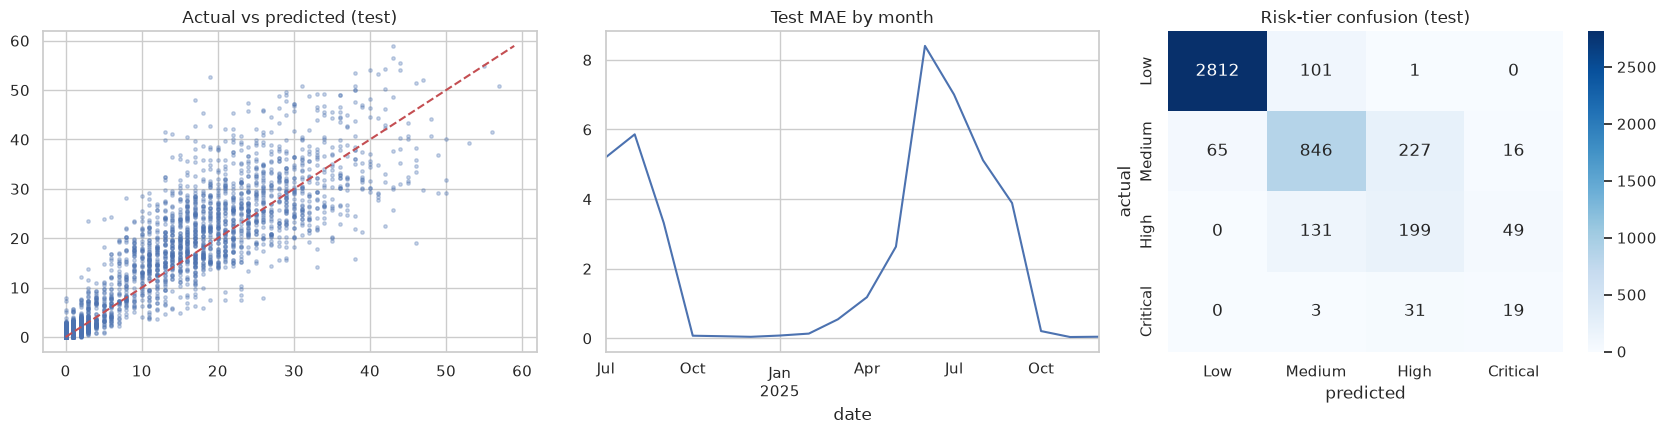

In [13]:
tp = pd.read_csv(ROOT/'reports/test_predictions.csv', parse_dates=['date'])
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
ax[0].scatter(tp.actual, tp.pred, s=6, alpha=.3); mx = tp[['actual','pred']].max().max(); ax[0].plot([0,mx],[0,mx],'r--'); ax[0].set_title('Actual vs predicted (test)')
(tp.assign(ae=(tp.actual-tp.pred).abs()).groupby(tp.date.dt.to_period('M')).ae.mean()).plot(ax=ax[1], title='Test MAE by month')
cm = np.array(M['test_by_window'][C.MAIN_WINDOW]['tier_confusion']); sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=C.RISK_TIERS, yticklabels=C.RISK_TIERS, ax=ax[2]); ax[2].set_xlabel('predicted'); ax[2].set_ylabel('actual'); ax[2].set_title('Risk-tier confusion (test)')
plt.tight_layout(); plt.show()

### Prediction intervals
Quantile (10%/90%) gradient-boosting models with split-conformal (CQR) calibration on the validation set. **Limitations:** exchangeability is assumed between validation and deployment; with count data heavy in zeros the interval is conservative (test coverage exceeds the nominal 80%), and coverage can degrade under distribution shift.

In [14]:
t = M['test_by_window'][C.MAIN_WINDOW]; print({k: round(t[k],3) for k in ['interval_coverage','interval_width']})
print('coverage by predicted level (test):'); print(((tp.actual>=tp.lo)&(tp.actual<=tp.hi)).groupby(pd.cut(tp.pred,[-1,3,10,22,36,99])).mean().round(2))

{'interval_coverage': 0.94, 'interval_width': 12.967}
coverage by predicted level (test):
pred
(-1, 3]     0.97
(3, 10]     0.89
(10, 22]    0.90
(22, 36]    0.90
(36, 99]    0.95
dtype: float64


### Drivers: grouped permutation importance (validation, rise in MAE when a group is shuffled)

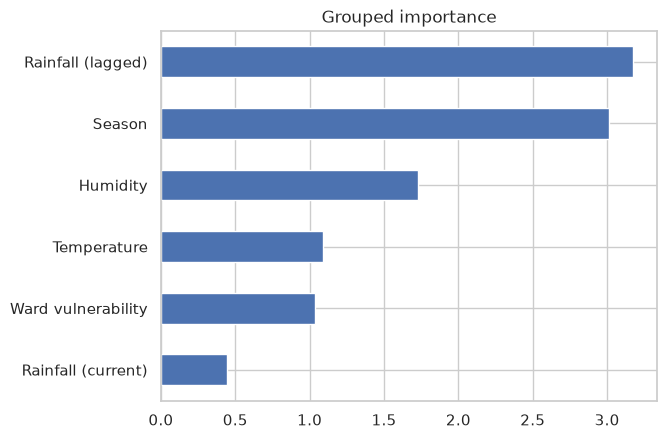

In [15]:
pd.Series(M['grouped_importance_val_MAE_increase']).sort_values().plot.barh(title='Grouped importance'); plt.show()

### Example inference (what the dashboard calls)

In [16]:
from src.predict import load_features, predict_one, explain_row
F = load_features()
print(predict_one(F, 'DNCC_Ward_01', '2025-08-04'))
explain_row(F[(F.ward_id=='DNCC_Ward_01')&(F.date=='2025-08-04')]).round(2)

{'ward_id': 'DNCC_Ward_01', 'date': '2025-08-04', 'window': 'Weeks 2-4 ahead (total)', 'predicted_cases': np.float64(27.7), 'interval_80': [np.float64(0.0), np.float64(37.2)], 'risk_tier': 'High'}


,driver,effect_cases
0,Ward vulnerability,4.33
1,Humidity,0.31
2,Season,0.00
3,Rainfall (current),0.00
4,Rainfall (lagged),-1.25
5,Temperature,-2.19


## 6. Automated leakage audit and synthetic-data check
Impressive metrics are only meaningful if the pipeline cannot cheat. `src/audit.py` runs five checks using **training/validation data only** (the test period is never touched):
1. **Causal direction** – cases should correlate more with *past* rain at a 2-4 week lag than with *future* rain.
2. **Permutation placebo** – shuffle the target within each ward; a leak-free pipeline must collapse to R² ≈ 0.
3. **Ablations** – how much do ward attributes + season explain *without any weather*?
4. **Ward × week-of-year climatology** – a much stronger seasonal reference than "same week last year".
5. **Synthetic signature** – R² > 0.9 is unusual for real surveillance data.

In [17]:
from src import audit
import pandas as pd
A = audit.leakage_audit()
pd.DataFrame({'past rain lag (w)': A['corr_cases_vs_past_rain_lag']}).T.round(3).style.set_caption('corr(cases_t, rain_{t-k}) averaged over wards')


,0,1,2,3,4,5,6
past rain lag (w),0.553000,0.613000,0.697000,0.779000,0.707000,0.562000,0.515000


In [18]:
print('Future-rain lead correlations (confounded by shared seasonality):', {k: round(v,2) for k,v in A['corr_cases_vs_future_rain_lead'].items()})
rows = {k: A[k] for k in ['placebo_shuffled_target_val','static_plus_season_only_val','ward_week_climatology_val','full_weather_model_val']}
names = {'placebo_shuffled_target_val':'Placebo (shuffled target)','static_plus_season_only_val':'Ward attributes + season only (no weather)',
         'ward_week_climatology_val':'Ward x week-of-year climatology','full_weather_model_val':'Full weather-lag model'}
tab = pd.DataFrame(rows).T.rename(index=names).round(3); display(tab)
gain = 1 - A['full_weather_model_val']['MAE'] / A['ward_week_climatology_val']['MAE']
print(f"Weather-lag features cut validation MAE by {gain:.0%} versus the strongest seasonal reference; the placebo R2 = {A['placebo_shuffled_target_val']['R2']:.2f} confirms no target leakage.")
print('Residual lag-1 autocorrelation (val):', round(A['val_residual_lag1_autocorr_mean'],2), '(overlapping 3-week target windows induce some of this)')


Future-rain lead correlations (confounded by shared seasonality): {1: 0.49, 2: 0.46, 3: 0.37, 4: 0.29}


,MAE,RMSE,R2
Placebo (shuffled target),9.876,13.054,0.038
Ward attributes + season only (no weather),2.556,5.535,0.827
Ward x week-of-year climatology,2.590,5.635,0.821
Full weather-lag model,1.825,3.804,0.918


Weather-lag features cut validation MAE by 30% versus the strongest seasonal reference; the placebo R2 = 0.04 confirms no target leakage.
Residual lag-1 autocorrelation (val): 0.58 (overlapping 3-week target windows induce some of this)


**Interpretation.** Past-rain correlation peaks at a **3-week lag**, matching the 2-4 week breeding clock, and exceeds future-rain correlation (which only reflects shared seasonality). The shuffled-target placebo collapses to R² ≈ 0, so features contain no target leakage. Note, however, that ward attributes + season alone already reach R² ≈ 0.83: **most of the explainable signal is ward vulnerability × seasonality, and lagged weather adds a further ~30% MAE reduction**. Together with R² > 0.9 on validation, this is the signature of a **synthetic dataset** – results are an upper bound for the method, not evidence of real-world accuracy, and must be re-validated on real surveillance data.

## 7. Hyper-parameter check (validation only)
Twelve random configurations of the selected HistGradientBoosting-Poisson model are compared with the default on the **validation** period. A tuned configuration is adopted only if it beats the default by more than 2% MAE (otherwise the simpler, already-validated default stays, avoiding validation over-fitting).

In [19]:
H = audit.tune_hgb(n_iter=12)
display(H.head(6).round(3))
d = float(H.loc[H.name=='default','MAE'].iloc[0]); b = float(H.MAE.iloc[0]); rel = (d-b)/d
print(f"Default MAE {d:.3f} vs best tuned {b:.3f} -> gain {rel:.1%}; adopted: {rel>0.02}")


,name,max_leaf_nodes,learning_rate,max_iter,min_samples_leaf,l2_regularization,MAE,RMSE,R2,fit_s
0,rs9,32,0.05,500,60,10.0,1.819,3.798,0.919,1.5
1,default,24,0.05,300,30,1.0,1.825,3.804,0.918,1.7
2,rs4,16,0.05,200,100,10.0,1.844,3.834,0.917,1.0
3,rs10,24,0.03,300,30,1.0,1.850,3.862,0.916,1.7
4,rs3,24,0.05,200,100,1.0,1.856,3.913,0.914,1.1
5,rs5,24,0.05,500,60,1.0,1.857,3.881,0.915,1.2


Default MAE 1.825 vs best tuned 1.819 -> gain 0.3%; adopted: False


## 7b. Early-outbreak detection quality, calibration, forecast strategy and input quality
Added in the final upgrade. All selection (alert threshold, forecast strategy) uses **validation** data only; test numbers are reporting only.

In [20]:
t = M['test_by_window'][C.MAIN_WINDOW]
op = pd.DataFrame([
  {'operating point': 'Tier >= High', 'recall': t['HC_recall'], 'precision': t['HC_precision'], 'false_alarm_rate': t['HC_false_alarm_rate']},
  {'operating point': 'Watch flag (sensitive, validation-chosen)', 'recall': t['ALERT_recall'], 'precision': t['ALERT_precision'], 'false_alarm_rate': t['ALERT_false_alarm_rate']}])
print('High/Critical PR-AUC (test):', round(t['HC_PR_AUC'], 3))
print('NOTE: the watch-flag false-alarm cap was 10% on validation; on test it is', round(t['ALERT_false_alarm_rate'], 3), '(thresholds do not transfer perfectly across periods).')
op.round(3)

High/Critical PR-AUC (test): 0.641
NOTE: the watch-flag false-alarm cap was 10% on validation; on test it is 0.193 (thresholds do not transfer perfectly across periods).


,operating point,recall,precision,false_alarm_rate
0,Tier >= High,0.690,0.550,0.060
1,"Watch flag (sensitive, validation-chosen)",0.986,0.352,0.193


In [21]:
cal = pd.read_csv(ROOT/'reports/interval_calibration_test.csv')
print('80% interval coverage by predicted-risk quintile (test):')
cal.round(3)

80% interval coverage by predicted-risk quintile (test):


,bin,n,mean_pred,mean_actual,coverage,width
0,0,900,0.018,0.020,0.980,0.248
1,1,900,0.071,0.059,0.964,0.743
2,2,900,1.784,1.661,0.950,5.761
3,3,900,15.074,14.361,0.894,22.949
4,4,900,30.599,25.883,0.911,35.136


In [22]:
hs = pd.read_csv(ROOT/'reports/horizon_strategy_validation.csv')
print('Mean validation MAE by strategy:'); print(hs.groupby('strategy').MAE.mean().round(3).to_string())
hs.round(3)

Mean validation MAE by strategy:
strategy
derived (window/3)           1.101
direct (per-horizon)         1.006
pooled (+horizon feature)    1.008


,horizon_weeks,strategy,n,MAE,RMSE,R2
0,2,direct (per-horizon),4440,0.916,2.038,0.825
1,2,pooled (+horizon feature),4440,0.923,2.061,0.821
2,2,derived (window/3),4440,1.039,2.272,0.782
3,3,direct (per-horizon),4440,0.965,2.139,0.807
4,3,pooled (+horizon feature),4440,0.948,2.076,0.818
5,3,derived (window/3),4440,0.977,2.110,0.812
6,4,direct (per-horizon),4440,1.138,2.411,0.755
7,4,pooled (+horizon feature),4440,1.154,2.511,0.734
8,4,derived (window/3),4440,1.288,2.702,0.692


In [23]:
from src.quality import data_quality_report
print(json.dumps(data_quality_report(raw), indent=1))

{
 "rows": 31320,
 "wards": 60,
 "date_min": "2016-01-04",
 "date_max": "2025-12-29",
 "duplicate_ward_weeks": 0,
 "missing_cells": {
  "avg_temp_c": 0,
  "rainfall_mm": 0,
  "relative_humidity_pct": 0,
  "dengue_cases": 0
 },
 "wards_with_calendar_gaps": 0,
 "negative_values": 0,
 "humidity_out_of_range": 0,
 "zero_case_share": 0.5803320561941252
}


## 8. Operational inference: multi-week forecast and what-if scenario
`src/scenario.py` rebuilds the lag features from a raw 9-week weather history with the *same* feature code and bundle used in training and in the dashboard. Below: the multi-week forecast (with 80% intervals) for one ward, and the effect of a hypothetical heavy-rain event in the last 4 weeks.

,window,pred,lo,hi,tier,alert
0,Weeks 2-4 ahead (total),27.7,0.0,37.2,High,True
1,Week 2 ahead,9.3,0.2,15.6,High,True
2,Week 3 ahead,10.0,0.0,16.6,Critical,True
3,Week 4 ahead,8.5,0.0,17.5,High,True


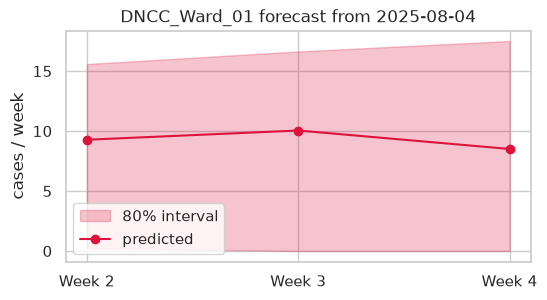

observed weather         ->   27.7 cases (0-37), tier High
rain x0 (last 5 wks)     ->    4.9 cases (0-25), tier Low
rain x2 (last 5 wks)     ->   52.5 cases (0-64), tier Critical


In [24]:
import matplotlib.pyplot as plt, pandas as pd
from src import config as C
from src.predict import load_bundle, load_features
from src.scenario import all_horizons, apply_scenario, predict_history, ward_history
Bn, F = load_bundle(), load_features()
ward, date = 'DNCC_Ward_01', pd.Timestamp('2025-08-04')
mh = all_horizons(F[(F.ward_id==ward)&(F.date==date)], Bn)
display(mh.round(1))
wk = mh[mh.window.str.match(r"^Week \d")]
fig, ax = plt.subplots(figsize=(6,3)); x = range(len(wk))
ax.fill_between(x, wk.lo, wk.hi, alpha=.25, color='crimson', label='80% interval'); ax.plot(x, wk.pred, 'o-', color='crimson', label='predicted')
ax.set_xticks(list(x)); ax.set_xticklabels(['Week 2','Week 3','Week 4']); ax.set_ylabel('cases / week'); ax.set_title(f'{ward} forecast from {date.date()}'); ax.legend(); plt.show()
h = ward_history(F, ward, date)
for name, hh in {'observed weather': h, 'rain x0 (last 5 wks)': apply_scenario(h, 0.0, weeks=5), 'rain x2 (last 5 wks)': apply_scenario(h, 2.0, weeks=5)}.items():
    r = predict_history(hh, bundle=Bn); print(f"{name:24s} -> {r['pred']:6.1f} cases ({r['lo']:.0f}-{r['hi']:.0f}), tier {r['tier']}")


## 9. Final findings and deployment readiness
* **Validity:** chronological split with 4-week purge gap, untouched test period, shuffled-target placebo ≈ 0, per-ward lag construction verified by unit tests.
* **Value of weather lags:** MAE 1.83 (validation) vs 2.59 for ward×week climatology, 3.47 seasonal-naive, 5.38 persistence. Test MAE 2.62 vs 4.03 (seasonal-naive).
* **Caveats:** synthetic-looking data (R² > 0.9, smooth lag-3 peak) – treat as upper bound; tiers are dataset-relative, not official alert levels; intervals are conservative (94% coverage at nominal 80%); no live weather/case feed – a real deployment must distinguish *observed* from *forecast* weather and re-validate.
* **Readiness:** serialized joblib bundle, offline inference, no external APIs, 19 automated tests, Streamlit dashboard sharing the same pipeline.

## Caveats
- Data look synthetic; real-world accuracy must be re-validated.
- Tier cut-points are relative (train-set 60/85/95th percentiles of the window total), not clinical thresholds.
- Test period was evaluated once per window; nothing was tuned on it.